In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import odeint
from scipy.optimize import curve_fit

# Configuration du style visuel (Thème académique)
sns.set_theme(style="ticks", context="talk")
plt.rcParams['figure.figsize'] = [16, 9]
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.5

print("Environnement configuré.")

Environnement configuré.


In [3]:
# Chargement des données brutes (JHU)
url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
df_raw = pd.read_csv(url)

# Filtrage pour la France (Somme des territoires et métropole)
df_france = df_raw[df_raw['Country/Region'] == 'France'].drop(columns=['Lat', 'Long', 'Country/Region'])
df_france = df_france.groupby('Province/State', dropna=False).sum().sum(axis=0).to_frame()

# Nettoyage et conversion temporelle
df_france.columns = ['Confirmés']
df_france.index = pd.to_datetime(df_france.index)

# On coupe le début bruyant (on commence > 10.000 cas)
df_france = df_france[df_france['Confirmés'] > 10000]

# Vecteurs pour le modèle
y_real = df_france['Confirmés'].values.astype(float)
x_days = np.arange(len(y_real))
N = 67000000  # Population approx. France

print(f"Données chargées : {len(df_france)} jours d'analyse.")

Données chargées : 1086 jours d'analyse.


C:\Users\pedro\AppData\Local\Temp\ipykernel_4620\408151868.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_france.index = pd.to_datetime(df_france.index)


In [4]:
# 1. Modèle SIR Simple
def sir_model(y, t, N, beta, gamma):
    S, I, R = y
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    return dSdt, dIdt, dRdt

# 2. Modèle SIRS (Avec Réinfection)
def sirs_model(y, t, N, beta, gamma, xi):
    S, I, R, C = y # C = Compteur cumulatif
    dSdt = -beta * S * I / N + xi * R
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I - xi * R
    dCdt = beta * S * I / N
    return dSdt, dIdt, dRdt, dCdt

# 3. Modèle SIRS Dynamique (Beta variable dans le temps)
num_nodes = 13
x_nodes = np.linspace(0, len(x_days), num_nodes)

def get_beta_t(t, betas_array):
    return np.interp(t, x_nodes, betas_array)

def sirs_dynamic_model(y, t, N, gamma, xi, *betas_array):
    S, I, R, C = y
    beta_t = get_beta_t(t, betas_array)
    
    dSdt = -beta_t * S * I / N + xi * R
    dIdt = beta_t * S * I / N - gamma * I
    dRdt = gamma * I - xi * R
    dCdt = beta_t * S * I / N
    return dSdt, dIdt, dRdt, dCdt

# Fonctions "wrapper" pour l'optimisation
def fit_sir(x, beta, gamma):
    y0 = N - y_real[0], y_real[0], 0
    ret = odeint(sir_model, y0, x, args=(N, beta, gamma))
    return ret[:, 1] + ret[:, 2]

def fit_sirs(x, beta, gamma, xi):
    y0 = N - y_real[0], y_real[0], 0, y_real[0]
    ret = odeint(sirs_model, y0, x, args=(N, beta, gamma, xi))
    return ret[:, 3]

def fit_dynamic(x, gamma, xi, *betas_array):
    y0 = N - y_real[0], y_real[0], 0, y_real[0]
    ret = odeint(sirs_dynamic_model, y0, x, args=(N, gamma, xi, *betas_array))
    return ret[:, 3]

In [4]:
print("Calcul des paramètres optimaux...")

# A. Modèle SIR Simple
# Stratégie : On entraîne SEULEMENT sur la 1ère vague (150 premiers jours)
# pour montrer que le modèle échoue à prédire la suite.
limit_sir = 150
popt_sir, _ = curve_fit(fit_sir, x_days[:limit_sir], y_real[:limit_sir], p0=[0.5, 0.1])
y_sir = fit_sir(x_days, *popt_sir) # Projection sur toute la période
print(f"1. SIR Classique ajusté (Entraînement : {limit_sir} jours).")

# B. Modèle SIRS (Complet)
# Bounds : Beta/Gamma > 0, Xi (perte immunité) petit
popt_sirs, _ = curve_fit(fit_sirs, x_days, y_real, p0=[0.2, 0.1, 0.001], bounds=([0,0,0], [5,1,0.1]))
y_sirs = fit_sirs(x_days, *popt_sirs)
print("2. SIRS ajusté.")

# C. Modèle SIRS Dynamique
print("3. Ajustement du modèle Dynamique (Patience...)...")
p0_dyn = [0.1, 0.002] + [0.15] * num_nodes
bounds_low = [0, 0] + [0] * num_nodes
bounds_high = [1, 0.1] + [5.0] * num_nodes

try:
    popt_dyn, _ = curve_fit(fit_dynamic, x_days, y_real, p0=p0_dyn, bounds=(bounds_low, bounds_high), maxfev=25000)
    y_dyn = fit_dynamic(x_days, *popt_dyn)
    print("-> Succès de l'optimisation dynamique !")
except Exception as e:
    print(f"-> Échec : {e}")
    y_dyn = np.zeros_like(y_real)

Calcul des paramètres optimaux...
1. SIR Classique ajusté (Entraînement : 150 jours).
2. SIRS ajusté.
3. Ajustement du modèle Dynamique (Patience...)...
-> Succès de l'optimisation dynamique !


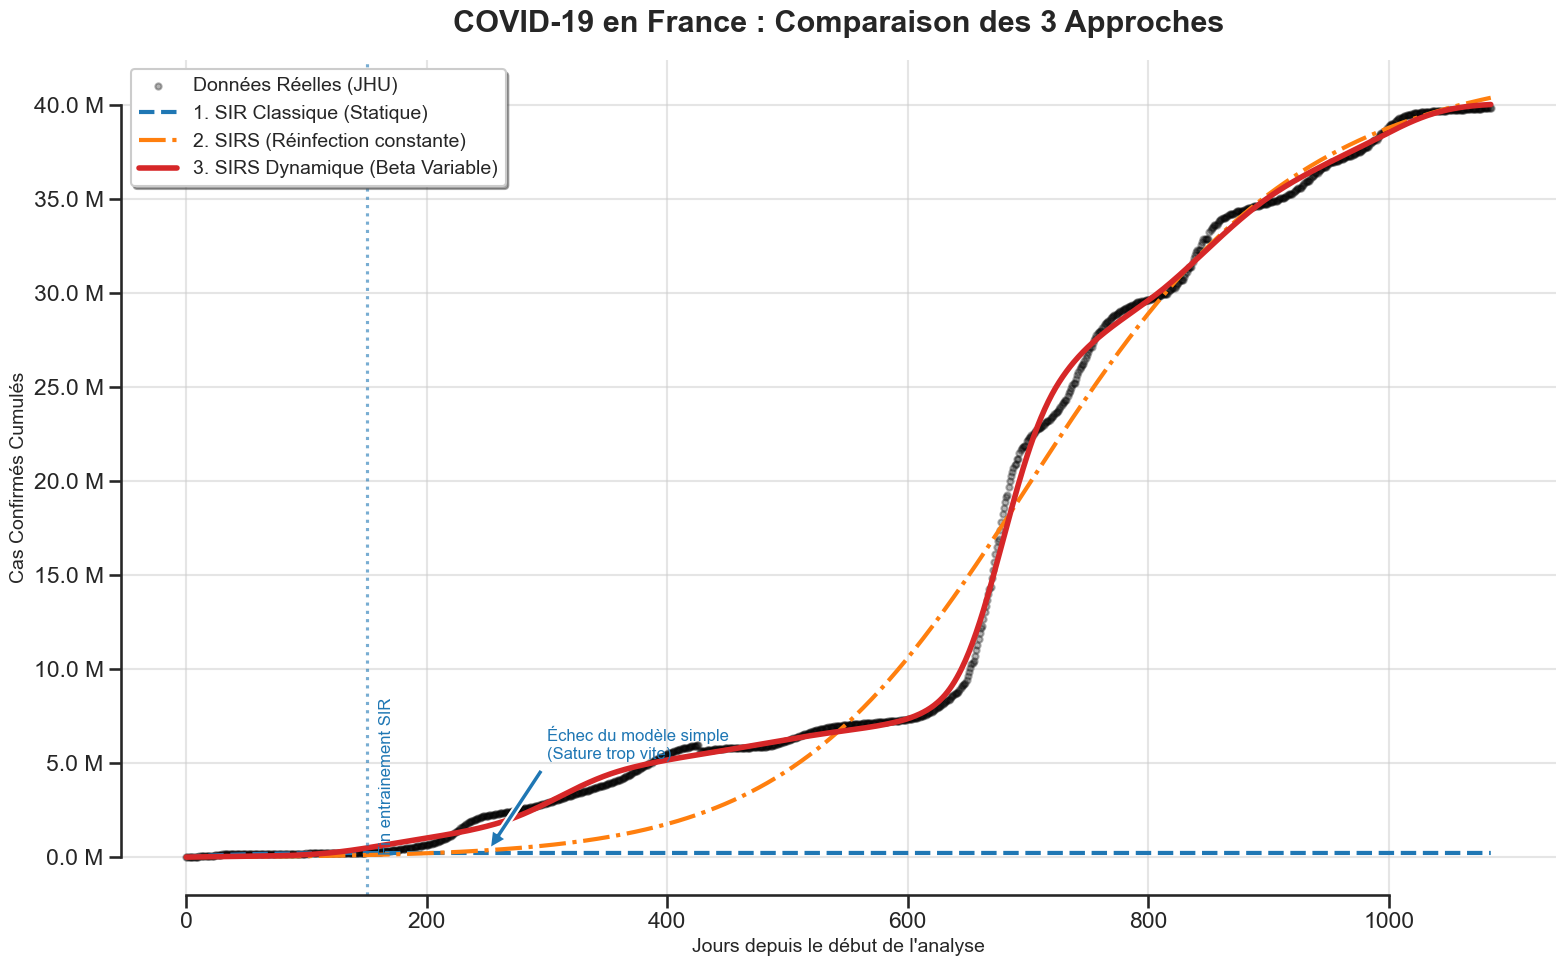

In [5]:
fig, ax = plt.subplots(figsize=(16, 10))

# 1. Données Réelles
ax.scatter(x_days, y_real, color='black', alpha=0.3, s=20, label='Données Réelles (JHU)')

# 2. SIR Simple (Bleu)
ax.plot(x_days, y_sir, color='#1f77b4', linestyle='--', linewidth=3, 
        label='1. SIR Classique (Statique)')

# 3. SIRS (Orange)
ax.plot(x_days, y_sirs, color='#ff7f0e', linestyle='-.', linewidth=3, 
        label='2. SIRS (Réinfection constante)')

# 4. SIRS Dynamique (Rouge)
ax.plot(x_days, y_dyn, color='#d62728', linestyle='-', linewidth=4, 
        label='3. SIRS Dynamique (Beta Variable)')

# Décoration
ax.set_title("COVID-19 en France : Comparaison des 3 Approches", fontsize=22, fontweight='bold', pad=20)
ax.set_xlabel("Jours depuis le début de l'analyse", fontsize=14)
ax.set_ylabel("Cas Confirmés Cumulés", fontsize=14)

# Formatage axe Y en Millions
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:.1f} M".format(x/1e6)))

# Ligne verticale limite SIR
ax.axvline(x=limit_sir, color='#1f77b4', linestyle=':', alpha=0.6)
ax.text(limit_sir+10, y_real[limit_sir], 'Fin entrainement SIR', color='#1f77b4', rotation=90, fontsize=12)

# Annotation Divergence
ax.annotate('Échec du modèle simple\n(Sature trop vite)', 
            xy=(250, y_sir[250]), xytext=(300, y_sir[250]+5000000),
            arrowprops=dict(facecolor='#1f77b4', shrink=0.05), fontsize=12, color='#1f77b4')

ax.legend(fontsize=14, loc='upper left', frameon=True, shadow=True)
sns.despine(trim=True)

plt.tight_layout()
plt.show()

In [ ]:
# Récupération des betas dynamiques
betas_found = popt_dyn[2:]
beta_curve = [get_beta_t(t, betas_found) for t in x_days]

plt.figure(figsize=(16, 6))

# Notez le r devant la chaine pour éviter l'erreur LaTeX
plt.plot(x_days, beta_curve, color='purple', linewidth=2, label=r'Taux de Transmission Estimé ($\beta$)')
plt.fill_between(x_days, beta_curve, color='purple', alpha=0.1)

plt.title(r"Dynamique de l'Épidémie : Variation du paramètre $\beta(t)$ en France", fontsize=18)
plt.ylabel(r"Beta ($\beta$)", fontsize=14)
plt.xlabel("Jours", fontsize=14)

# Ligne moyenne
beta_medio = np.mean(beta_curve)
plt.axhline(beta_medio, color='gray', linestyle='--', label=f'Moyenne : {beta_medio:.2f}')

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=12)

plt.show()

In [ ]:
# Calcul RMSE (Erreur Quadratique Moyenne)
def get_rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

rmse_sir = get_rmse(y_real, y_sir)
rmse_sirs = get_rmse(y_real, y_sirs)
rmse_dyn = get_rmse(y_real, y_dyn)

print("=== TABLEAU COMPARATIF DES ERREURS (RMSE) ===")
print(f"{'MODÈLE':<30} | {'RMSE (Millions)':<15}")
print("-" * 50)
print(f"{'1. SIR Classique':<30} | {rmse_sir/1e6:.2f} M")
print(f"{'2. SIRS (Réinfection)':<30} | {rmse_sirs/1e6:.2f} M")
print(f"{'3. SIRS Dynamique':<30} | {rmse_dyn/1e6:.2f} M")

print("\nConclusion :")
print("Le modèle simple est incapable de suivre la réalité après la 1ère vague.")
print("Le modèle dynamique réduit l'erreur drastiquement en s'adaptant aux vagues successives.")